# Laboratorio 1

### Librerías

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import het_arch
from scipy.stats import boxcox
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sktime.forecasting.naive import NaiveForecaster
from prophet import Prophet
from statsmodels.tsa.holtwinters import ExponentialSmoothing, SimpleExpSmoothing
from scipy.stats import linregress
import matplotlib.dates as mdates

In [19]:
#pip install sktime

### Importación de datos.

In [20]:
df = pd.read_csv('DATOS_LIMPIOS.csv')
df.head(2)

,Vía,Frontera,País,Región,Región dos,Regiones OMT,MCEO,Agrupación Residencia,Tipo de Viajero,Viajero,Fecha
0,Aérea,01 La Aurora,Albania,OTROS EUROPEOS,Europa,EUROPA MERIDIONAL,08 OTROS,Europa,Turista,1.0,2009-01-01
1,Aérea,01 La Aurora,Alemania,EUROPA,Europa,EUROPA OCCIDENTAL,04 EUROPA,Europa,Turista,716.0,2009-01-01


### Serie de tiempo.

In [21]:
df_filtro = df[(df['Tipo de Viajero'].isin(['Excursionista', 'Turista']) & (df['País'] == 'Estados Unidos de América'))]
df_fecha = df_filtro.groupby('Fecha')['Viajero'].sum().round(0).astype(int)
serie = df_fecha.to_frame('Viajero')
serie = serie.sort_values(by='Fecha', ascending=True)
serie.index = pd.to_datetime(serie.index)
serie.index = serie.index.to_period('M')

### Estimando la tendencia en la pandemia.

In [22]:
inicio = pd.Period('2020-03', freq='M')
fin = pd.Period('2022-12', freq='M')

In [23]:
y_train = serie.loc[serie.index < inicio, 'Viajero']
modelo = NaiveForecaster(strategy='last', sp=12)
modelo.fit(y_train)
fh = range(len(y_train) + 1, len(y_train) + len(pd.period_range(inicio, fin, freq='M')) + 1)
predicciones = modelo.predict(fh=fh)

# Reindexando si no existen
serie = serie.reindex(serie.index.union(pd.period_range(inicio, fin, freq='M')), fill_value=0)
serie.loc[inicio:fin, 'Viajero'] = predicciones.to_numpy()
serie['Viajero'] = serie['Viajero'].round().astype(int)
serie.index = serie.index.to_timestamp()

### Separación de datos.

In [24]:
filas, columnas = serie.shape
fil_entrenamiento = int(filas * 0.7)
entrenamiento = serie.iloc[:fil_entrenamiento+1]
prueba = serie.iloc[fil_entrenamiento+1:]

In [25]:
serie.head(2)

,Viajero
2009-01-01,23944
2009-02-01,23874


### Gráfico de descomposición de la serie temporal.

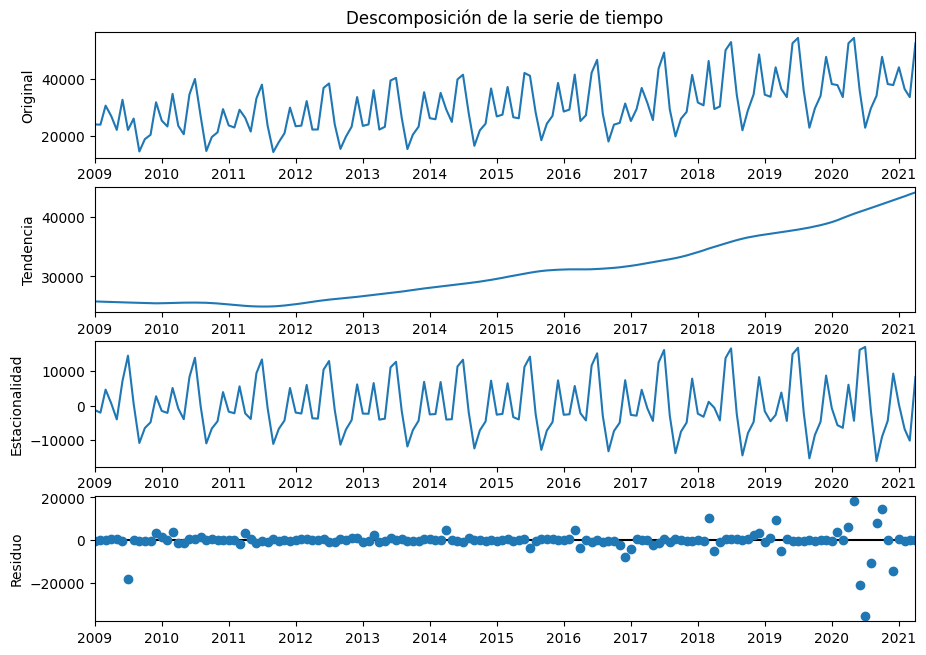

In [26]:
stl = STL(entrenamiento, period=12, robust=True)

descomposicion = stl.fit()
fig = descomposicion.plot()
fig.set_size_inches(10, 7)
axes = fig.axes

for ax in axes:
    ax.tick_params(axis='x', labelbottom=True)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

axes[0].set_title('Descomposición de la serie de tiempo')
axes[0].set_ylabel('Original')
axes[1].set_ylabel('Tendencia')
axes[2].set_ylabel('Estacionalidad')
axes[3].set_ylabel('Residuo')
plt.show()

### Tendencia de toda la serie.

In [27]:
x = range(len(serie))
tendencia = linregress(x, serie['Viajero']).slope
tendencia

np.float64(158.6239221491903)

### Valor alpha a utilizar.

In [28]:
alpha = 0.05

### Verificación de estacionariedad en media (Serie original).

$\alpha = 0.05$

$\textbf{ADF}$  
$H_0:$ La serie no es estacionaria en media.  
$H_a:$ La serie es estacionaria en media.

$\textbf{KPSS}$   
$H_0:$ La serie es estacionaria en media.  
$H_a:$ La serie no es estacionaria en media.

In [29]:
def estacionariedad_media(datos, alpha):
    adf = adfuller(datos, regression="c")[1]
    kpss_test = kpss(datos, regression="c", nlags="auto")[1]

    if adf < alpha:
        texto_1 = f'Prueba ADF: Se rechaza la hipótesis nula, ya que el valor p = {adf} < alpha = {alpha}. La serie es estacionaria en media.'
    else:
        texto_1 = f'Prueba ADF: No se rechaza la hipótesis nula, ya que el valor p = {adf} >= alpha = {alpha}. La serie se considera no estacionaria en media.'

    if kpss_test < alpha:
        texto_2 = f'Prueba KPSS: Se rechaza la hipótesis nula, ya que el valor p = {kpss_test} < alpha = {alpha}. La serie no es estacionaria en media.'
    else:
        texto_2 = f'Prueba KPSS: No se rechaza la hipótesis nula, ya que el valor p = {kpss_test} >= alpha = {alpha}. La serie se considera estacionaria en media.'

    print(texto_1)
    print(texto_2)

    if (adf <= alpha and kpss_test <= alpha) or (adf > alpha and kpss_test > alpha):
        print('Las pruebas no coinciden, pero se realizará diferenciación, ya que una muestra la no estacionariedad de la media.')

estacionariedad_media(serie, alpha)

Prueba ADF: No se rechaza la hipótesis nula, ya que el valor p = 0.9989189488924445 >= alpha = 0.05. La serie se considera no estacionaria en media.
Prueba KPSS: Se rechaza la hipótesis nula, ya que el valor p = 0.01 < alpha = 0.05. La serie no es estacionaria en media.


C:\Users\ricro\AppData\Local\Temp\ipykernel_30212\1874529149.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_test = kpss(datos, regression="c", nlags="auto")[1]


### Verificación de estacionariedad en media (Serie diferenciada).

In [30]:
estacionariedad_media(entrenamiento.diff()[1:], alpha)

Prueba ADF: Se rechaza la hipótesis nula, ya que el valor p = 1.0237604095961512e-13 < alpha = 0.05. La serie es estacionaria en media.
Prueba KPSS: No se rechaza la hipótesis nula, ya que el valor p = 0.1 >= alpha = 0.05. La serie se considera estacionaria en media.


C:\Users\ricro\AppData\Local\Temp\ipykernel_30212\1874529149.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_test = kpss(datos, regression="c", nlags="auto")[1]


### Verificación de estacionariedad en varianza (Serie original).

$\alpha = 0.05$

$\textbf{ARCH}$  
$H_0:$ La serie es estacionaria en varianza.  
$H_a:$ La serie no es estacionaria en varianza.

In [31]:
def estacionariedad_varianza(datos, alpha):
    arch = het_arch(datos)[1]

    if arch < alpha:
        texto_1 = f'Prueba ARCH: Se rechaza la hipótesis nula, ya que el valor p = {arch} < alpha = {alpha}. La serie no es estacionaria en varianza. Se hará una transformación.'
    else:
        texto_1 = f'Prueba ARCH: No se rechaza la hipótesis nula, ya que el valor p = {arch} >= alpha = {alpha}. La serie se considera estacionaria en varianza.'

    print(texto_1)
estacionariedad_varianza(entrenamiento, alpha)

Prueba ARCH: Se rechaza la hipótesis nula, ya que el valor p = 1.9802266439353693e-08 < alpha = 0.05. La serie no es estacionaria en varianza. Se hará una transformación.


### Verificación de estacionariedad en varianza (Serie box cox).

In [32]:
entrenamiento_box_cox, lambda_optimo = boxcox(entrenamiento['Viajero'])
estacionariedad_varianza(entrenamiento_box_cox, alpha)

Prueba ARCH: Se rechaza la hipótesis nula, ya que el valor p = 1.0559870234402274e-07 < alpha = 0.05. La serie no es estacionaria en varianza. Se hará una transformación.


No se puede quitar la no estacionariedad de la varianza, se seguirá con el modelaje, pero se recalca este problema.

### Transformaciones hechas.

In [33]:
entrenamiento_transformado = entrenamiento

### Elección de parámetro d.

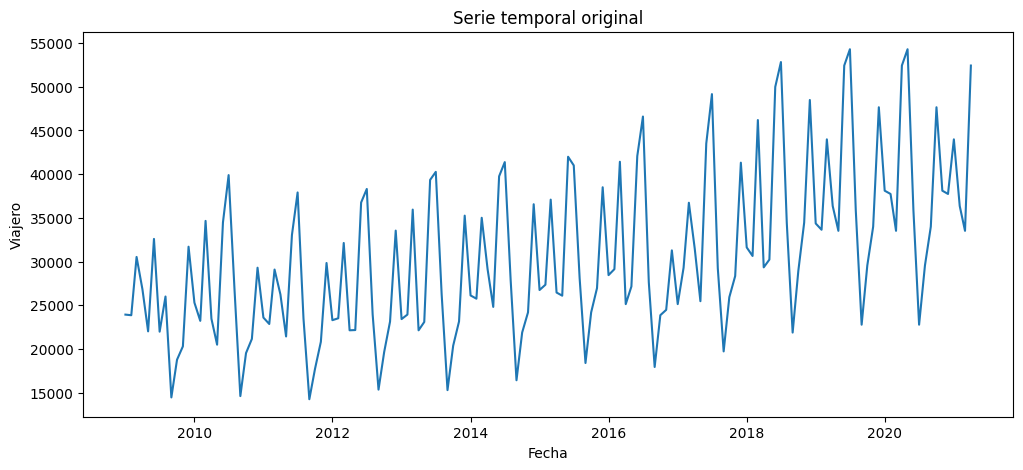

In [34]:
y = entrenamiento
plt.figure(figsize=(12, 5))
plt.plot(y)
plt.title("Serie temporal original")
plt.xlabel("Fecha")
plt.ylabel("Viajero")
plt.show()

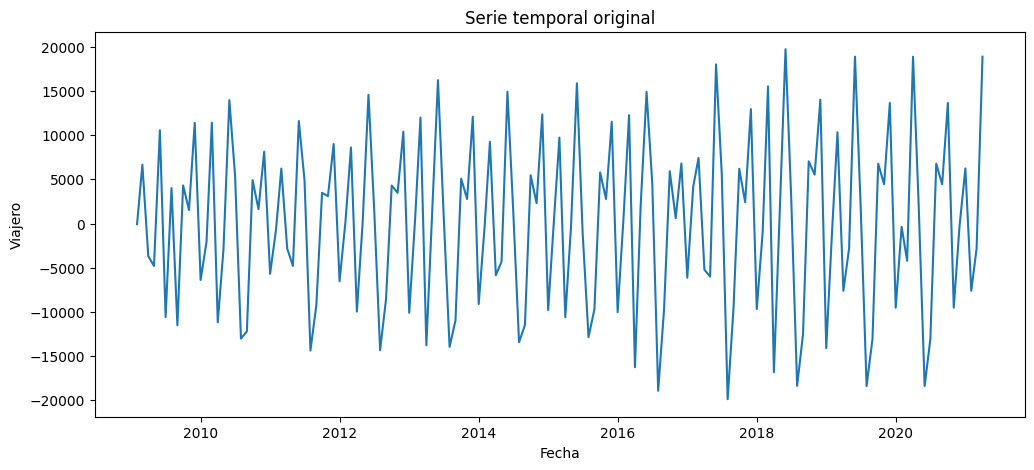

In [35]:
y = entrenamiento.diff(1).dropna()
plt.figure(figsize=(12, 5))
plt.plot(y)
plt.title("Serie temporal original")
plt.xlabel("Fecha")
plt.ylabel("Viajero")
plt.show()

La serie logra estabilizarse en media con una diferencia regular.

### Elección del parámetro p y q.

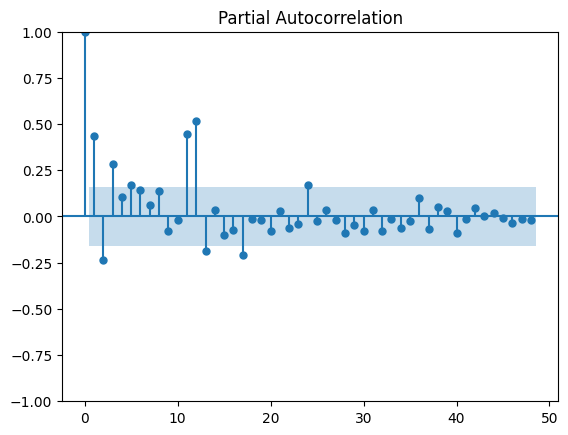

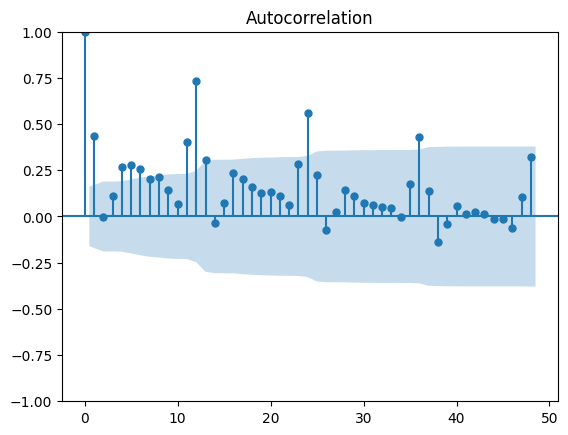

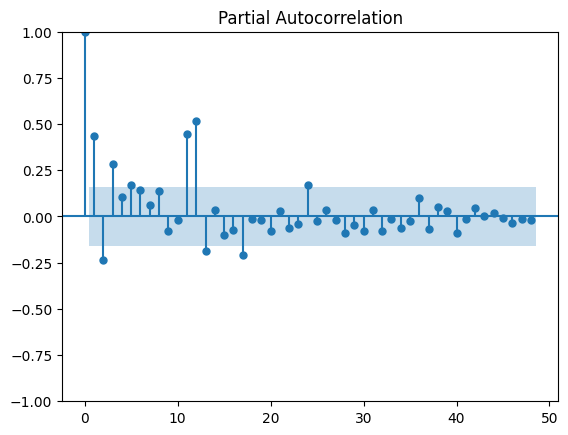

In [36]:
plot_acf(entrenamiento_transformado, lags=48)
plot_pacf(entrenamiento_transformado, lags=48)

El PACF cae en el cuarto retardo y el ACF cae en el segundo retardo.

### Elección de parámetro D.

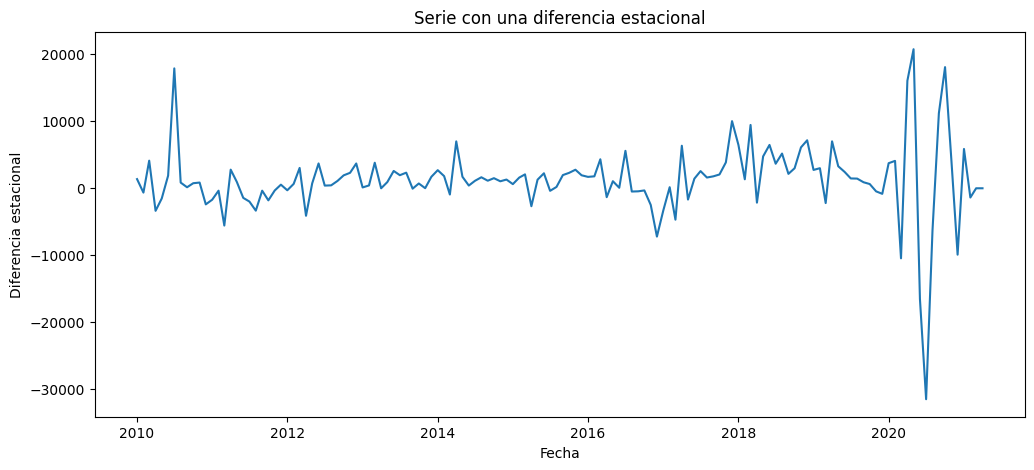

In [37]:
m = 12

y_diff_estacional = entrenamiento.diff(12)

plt.figure(figsize=(12, 5))
plt.plot(y_diff_estacional)
plt.title("Serie con una diferencia estacional")
plt.xlabel("Fecha")
plt.ylabel("Diferencia estacional")
plt.show()

La serie logra estabilizarse en media con una diferencia estacional.

### Elección del parámetro P y Q.

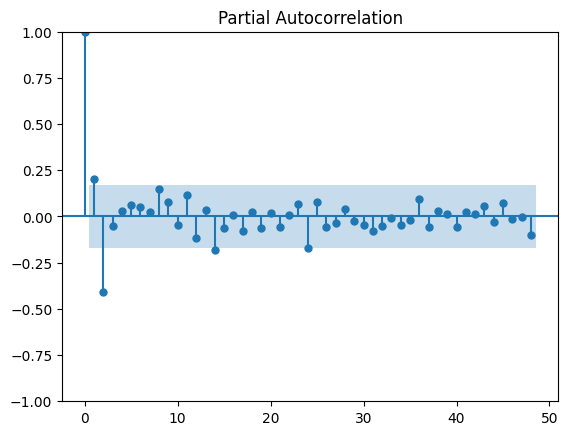

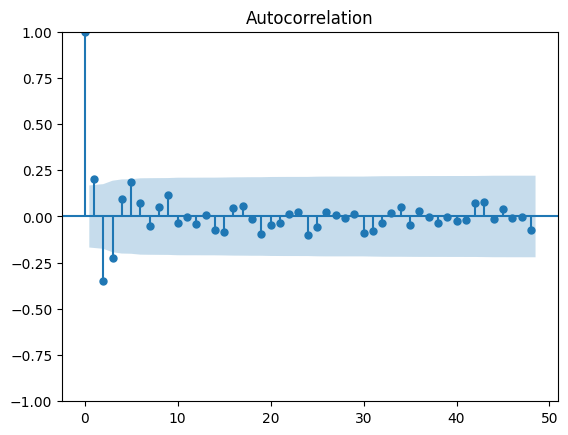

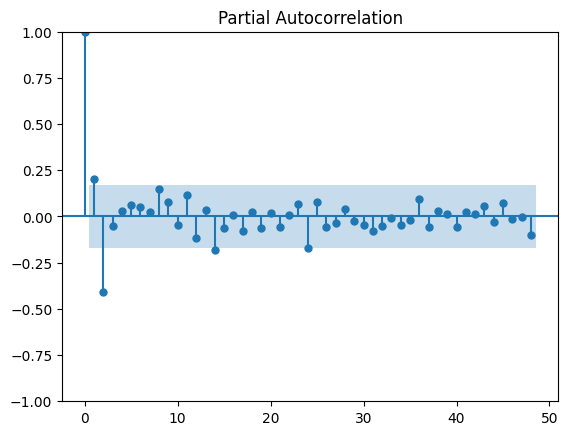

In [38]:
plot_acf(entrenamiento.diff(12).dropna(), lags=48)
plot_pacf(entrenamiento.diff(12).dropna(), lags=48)

El PACF cae en el cuarto retardo y el ACF caen en el terecer retardo.

### Elección de parámetros.

- d = 1. Debido a que las pruebas de estacionariedad demostraron media estacionaria después de una diferenciación.
- p = 2. Ya que el tercer retardo deja de ser significativo en el PACF.
- q = 1. Ya que el segundo retardo deja de ser significativo en el ACF.
- D = 1. Ya que la serie se estabiliza en media con una diferencia estacional.
- P = 2. Ya que el tercer retardo deja de ser significativo en el PACF.
- Q = 3. Ya que el cuarto retardo deja de ser significativo en el ACF.

### Entrenamiento de modelos SARIMA.

In [39]:
modelo_1 = SARIMAX(entrenamiento_transformado, order=(2, 1, 1), seasonal_order=(2, 1, 3, 12),
                   trend=None, enforce_stationarity=False, enforce_invertibility=False)
sarima_1 = modelo_1.fit(maxiter=500, disp=False)

In [40]:
modelo_2 = SARIMAX(entrenamiento_transformado, order=(1, 1, 1), seasonal_order=(2, 1, 2, 12),
                   trend=None, enforce_stationarity=False, enforce_invertibility=False)
sarima_2 = modelo_2.fit(maxiter=500, disp=False)

In [41]:
modelo_3 = SARIMAX(entrenamiento_transformado, order=(1, 1, 1), seasonal_order=(1, 2, 1, 12),
                   trend=None, enforce_stationarity=False, enforce_invertibility=False)
sarima_3 = modelo_3.fit(maxiter=500, disp=False)

### Comparación de los modelos.

In [42]:
modelos = {"SARIMA 1": sarima_1, "SARIMA 2": sarima_2, "SARIMA 3": sarima_3}

resultados = []

for nombre, modelo in modelos.items():
    residuos = modelo.resid.dropna()

    ljung_box = acorr_ljungbox(residuos, lags=[12], return_df=True)
    resultados.append({"Modelo": nombre, "AIC": modelo.aic, "BIC": modelo.bic, "Media residuos": residuos.mean(), 
                       "Ljung-Box p-value": ljung_box["lb_pvalue"].iloc[0]})

comparacion = pd.DataFrame(resultados).sort_values(by=["AIC", "BIC"])

print(comparacion)

     Modelo          AIC          BIC  Media residuos  Ljung-Box p-value
1  SARIMA 2  2200.699782  2219.539217     -380.486618       3.065281e-02
2  SARIMA 3  2224.440784  2237.897523      -75.253525       5.981832e-02
0  SARIMA 1  4216.104927  4239.277326        5.999171       4.641512e-14


El SARIMA 2 demostró ser mejor modelo teniendo un AIC, BIC menor que el de los otros. La media es en magnitud mucho más grande que el de los otros. Todos cumplen con la independencia de residuos ya que los valores p son menores a 0.05.  
Se eligirá el SARIMA 3 debido a su AIC y BIC menores.

### Otros modelos.

In [43]:
# Período de predicción.
periodo_estacional = 12

# Función que evalúa las métricas.
def metricas(y_real, y_pred):
    return {'MAE': mean_absolute_error(y_real, y_pred),
            'RMSE': np.sqrt(mean_squared_error(y_real, y_pred))}
predicciones = {}

In [44]:
# Métricas de los modelos SARIMA
modelos_sarima = {
    'SARIMA 1': sarima_1,
    'SARIMA 2': sarima_2,
    'SARIMA 3': sarima_3
}

for nombre, modelo in modelos_sarima.items():
    predicciones[nombre] = modelo.forecast(steps=len(prueba))

In [45]:
# Prophet
prophet_train = pd.DataFrame({'ds': entrenamiento_transformado.index,
                              'y': entrenamiento_transformado['Viajero']})

modelo_prophet = Prophet()
modelo_prophet.fit(prophet_train)
futuro = pd.DataFrame({'ds': prueba.index})
predicciones['Prophet'] = modelo_prophet.predict(futuro)['yhat'].values

19:56:50 - cmdstanpy - INFO - Chain [1] start processing
19:56:50 - cmdstanpy - INFO - Chain [1] done processing


In [46]:
# Holt-Winters
modelo_hw = ExponentialSmoothing(entrenamiento_transformado, trend="add", seasonal="add", seasonal_periods=periodo_estacional).fit()
predicciones["Holt-Winters"] = modelo_hw.forecast(len(prueba))

In [47]:
# Suavizamiento exponencial simple
modelo_ses = SimpleExpSmoothing(entrenamiento_transformado).fit(optimized=True)
predicciones["Suavizamiento exponencial"] = modelo_ses.forecast(len(prueba))

In [48]:
# Seasonal Naive
predicciones["Seasonal Naive"] = np.resize(entrenamiento_transformado.iloc[-periodo_estacional:].values, len(prueba))

In [49]:
# Comparación
resultados = []

for nombre, prediccion in predicciones.items():
    valores = metricas(prueba.values, np.asarray(prediccion))

    resultados.append({
        "Modelo": nombre,
        "MAE": valores["MAE"],
        "RMSE": valores["RMSE"],
        "AIC": modelos_sarima[nombre].aic
        if nombre in modelos_sarima else np.nan,
        "BIC": modelos_sarima[nombre].bic
        if nombre in modelos_sarima else np.nan
    })

comparacion = pd.DataFrame(resultados).sort_values("RMSE")

print(comparacion)
print("\nMejor modelo:", comparacion.iloc[0]["Modelo"])

                      Modelo           MAE          RMSE          AIC  \
4               Holt-Winters   8323.127760  10631.950115          NaN   
3                    Prophet   9530.715545  11717.833491          NaN   
1                   SARIMA 2   9286.722451  12508.959233  2200.699782   
5  Suavizamiento exponencial  13359.480051  16657.108244          NaN   
6             Seasonal Naive  11876.580645  18542.103853          NaN   
0                   SARIMA 1  14465.325622  18995.867416  4216.104927   
2                   SARIMA 3  17591.862161  25832.251647  2224.440784   

           BIC  
4          NaN  
3          NaN  
1  2219.539217  
5          NaN  
6          NaN  
0  4239.277326  
2  2237.897523  

Mejor modelo: Holt-Winters


### Elección del mejor modelo.

In [50]:
# Predicción del mejor modelo
indice = 0
mejor_modelo_nombre = comparacion.iloc[indice]["Modelo"]
print('Se selecciona el modelo:', mejor_modelo_nombre)
mejor_modelo = sarima_1

Se selecciona el modelo: Holt-Winters


Esto debido a que tiene menor RMSE y MAE que cualquier otro modelo.

### Gráfica de predicción.

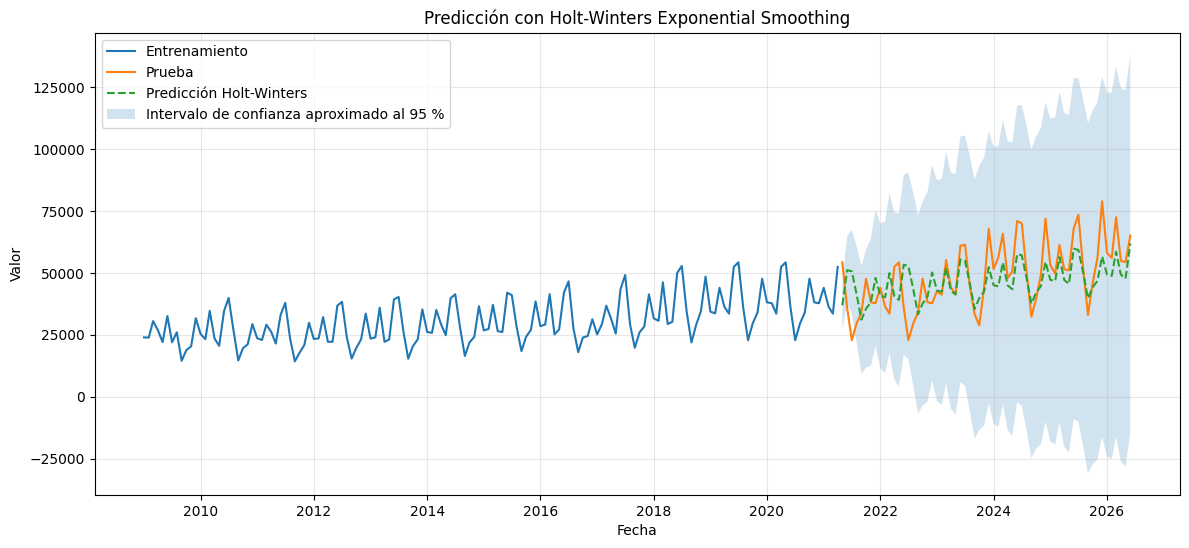

In [51]:
# Número de períodos que se desean predecir
n_periodos = len(prueba)

# Predicción con Holt-Winters
prediccion_hw = modelo_hw.forecast(steps=n_periodos)

# Asegurar que la predicción tenga el mismo índice que el conjunto de prueba
prediccion_hw = pd.Series(data=np.asarray(prediccion_hw), index=prueba.index,  name="prediccion_hw")


# Intervalo de confianza aproximado al 95 %
residuos_hw = pd.Series(modelo_hw.resid).dropna()
sigma = residuos_hw.std(ddof=1)
z = 1.96
horizonte = np.arange(1, n_periodos + 1)
error_pronostico = z * sigma * np.sqrt(horizonte)
limite_inferior = prediccion_hw - error_pronostico
limite_superior = prediccion_hw + error_pronostico

# Gráfica
plt.figure(figsize=(14, 6))
plt.plot(entrenamiento.index, entrenamiento, label="Entrenamiento")
plt.plot(prueba.index, prueba, label="Prueba")
plt.plot(prediccion_hw.index, prediccion_hw, linestyle="--", label="Predicción Holt-Winters")
plt.fill_between(prueba.index, limite_inferior.to_numpy(), limite_superior.to_numpy(), alpha=0.2, label="Intervalo de confianza aproximado al 95 %")
plt.title("Predicción con Holt-Winters Exponential Smoothing")
plt.xlabel("Fecha")
plt.ylabel("Valor")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

El modelo  Holt-Winters, logra seguir la tendencia de las visitas turísticas además se apega mejor a los datos que los otros modelos de países, incluso con el problema de que no fuera estacionario en varianza. El intervalo de confianza encierra correctamente todos los puntos.